# 02 - Exploración de ingeniería de características

**Proyecto 2 - Pipeline de Machine Learning (Predict Future Sales)**

Brady Monroy (15003165) y Luis Rodolfo Rodriguez

En este notebook se analiza y se elige **qué variables y qué transformaciones** se van a usar en el modelo, siguiendo
lo aprendido en el EDA (notebook 01). Todavía no se construye el pipeline: eso se hace en el notebook 03.

Pasos:
1. Cargar y limpiar los datos (misma limpieza del EDA).
2. Armar la tabla **mensual por par tienda-producto**, con 0 en los meses sin ventas.
3. **(1a)** Elegir los *lags* (ventas de meses anteriores) más útiles.
4. Crear las demás variables candidatas.
5. **(1b)** Probar al menos una operación de cada proceso de ingeniería de características.
6. **(1c)** Escribir la lista final de variables y transformaciones.

## Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from feature_engine.encoding import OneHotEncoder
from feature_engine.imputation import CategoricalImputer, MeanMedianImputer, RandomSampleImputer
from feature_engine.outliers import Winsorizer
from feature_engine.transformation import YeoJohnsonTransformer
from feature_engine.wrappers import SklearnTransformerWrapper
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_style("whitegrid")

# Rutas del proyecto (igual que en clase)
PROJ_ROOT = Path.cwd().parent
RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJ_ROOT / "data" / "processed"

RANDOM_STATE = 42

## 1. Carga y limpieza de los datos

Se aplica la misma limpieza que se decidió en el EDA (notebook 01, sección 4):
- Quitar las 6 filas duplicadas y la fila con precio negativo.
- Unir las tiendas repetidas: 0 → 57, 1 → 58 y 11 → 10.
- Las devoluciones (cantidades negativas) se conservan.

In [2]:
sales = pd.read_csv(RAW_DATA_DIR / "sales_train.csv")
items = pd.read_csv(RAW_DATA_DIR / "items.csv")
categories = pd.read_csv(RAW_DATA_DIR / "item_categories.csv")
shops = pd.read_csv(RAW_DATA_DIR / "shops.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv")

# Limpieza del EDA
sales = sales.drop_duplicates()
sales = sales[sales["item_price"] > 0]

sales.loc[sales["shop_id"] == 0, "shop_id"] = 57
sales.loc[sales["shop_id"] == 1, "shop_id"] = 58
sales.loc[sales["shop_id"] == 11, "shop_id"] = 10

print("Filas de ventas después de limpiar:", len(sales))

Filas de ventas después de limpiar: 2935842


## 2. Tabla mensual por par tienda-producto

La variable objetivo es `item_cnt_month`: la suma de `item_cnt_day` de cada par tienda-producto en cada mes.

**¿Qué pares se incluyen?** Cada mes se incluyen todas las combinaciones de las **tiendas que vendieron ese mes** con
los **productos que se vendieron ese mes** (en cualquier tienda). Si un par no tuvo ventas, su valor es **0**. Así el
modelo aprende también de los casos con cero ventas, que son muy comunes en `test.csv`.

Además, `item_cnt_month` se recorta al rango **[0, 20]**, como pide la competencia (lo vimos en el EDA).

In [3]:
# Paso 1: lista de combinaciones tienda-producto de cada mes
lista_meses = []

for mes in range(34):
    ventas_del_mes = sales[sales["date_block_num"] == mes]
    tiendas_del_mes = ventas_del_mes["shop_id"].unique()
    productos_del_mes = ventas_del_mes["item_id"].unique()

    # Todas las combinaciones tienda x producto de ese mes
    combinaciones = pd.MultiIndex.from_product(
        [[mes], tiendas_del_mes, productos_del_mes],
        names=["date_block_num", "shop_id", "item_id"],
    ).to_frame(index=False)

    lista_meses.append(combinaciones)

mensual = pd.concat(lista_meses, ignore_index=True)
print("Filas de la tabla mensual (meses 0 a 33):", len(mensual))

Filas de la tabla mensual (meses 0 a 33): 10913850


In [4]:
# Paso 2: sumar las ventas de cada par tienda-producto por mes
ventas_mensuales = sales.groupby(["date_block_num", "shop_id", "item_id"])["item_cnt_day"].sum()
ventas_mensuales = ventas_mensuales.reset_index().rename(columns={"item_cnt_day": "item_cnt_month"})

# Paso 3: unir con la tabla de combinaciones; los pares sin venta quedan en 0
mensual = mensual.merge(ventas_mensuales, on=["date_block_num", "shop_id", "item_id"], how="left")
mensual["item_cnt_month"] = mensual["item_cnt_month"].fillna(0)

# Paso 4: recortar la variable objetivo al rango [0, 20]
print("Valores fuera de [0, 20] antes de recortar:",
      ((mensual["item_cnt_month"] < 0) | (mensual["item_cnt_month"] > 20)).sum())
mensual["item_cnt_month"] = mensual["item_cnt_month"].clip(0, 20)

print("Porcentaje de filas con 0 ventas:", round((mensual["item_cnt_month"] == 0).mean() * 100, 2), "%")
mensual.head()

Valores fuera de [0, 20] antes de recortar: 12378
Porcentaje de filas con 0 ventas: 85.29 %


,date_block_num,shop_id,item_id,item_cnt_month
0,0,59,22154,1.000
1,0,59,2552,0.000
2,0,59,2554,0.000
3,0,59,2555,0.000
4,0,59,2564,0.000


In [5]:
# Paso 5: agregar el mes 34 (noviembre 2015) con los pares de test.csv.
# Su item_cnt_month es desconocido (es lo que se quiere predecir).
mes_34 = test[["shop_id", "item_id"]].copy()
mes_34["date_block_num"] = 34
mes_34["item_cnt_month"] = np.nan

mensual = pd.concat([mensual, mes_34], ignore_index=True)

# Usar tipos de datos más pequeños para ahorrar memoria
mensual["date_block_num"] = mensual["date_block_num"].astype("int16")
mensual["shop_id"] = mensual["shop_id"].astype("int16")
mensual["item_id"] = mensual["item_id"].astype("int32")
mensual["item_cnt_month"] = mensual["item_cnt_month"].astype("float32")

print("Filas totales (meses 0 a 34):", len(mensual))
print("Memoria usada:", round(mensual.memory_usage().sum() / 1024**2), "MB")

Filas totales (meses 0 a 34): 11128050
Memoria usada: 127 MB


**Interpretación (sección 2):**

- La tabla mensual de los meses 0 a 33 tiene **10,913,850 filas** (pares tienda-producto activos en cada mes).
- El **85.29% de las filas tiene 0 ventas**: la mayoría de productos no se vende en todas las tiendas cada mes. Por
  eso es importante incluir los ceros; si no, el modelo solo vería casos con ventas y sobreestimaría.
- Solo **12,378 valores** quedaron fuera de [0, 20] y se recortaron.
- Con el mes 34 (los 214,200 pares de `test.csv`), la tabla queda en **11,128,050 filas** y ocupa **127 MB** de
  memoria gracias a los tipos de datos pequeños (`int16`, `float32`).

## 3. (1a) Selección de lags

Un **lag** es la venta del mismo par tienda-producto en un mes anterior. Por ejemplo, `lag_1` es la venta del mes
pasado y `lag_12` la del mismo mes del año anterior.

**Cuidado con la fuga de información:** cada lag solo usa meses **anteriores** al que se predice. Para construir
`lag_k`, a la tabla se le suma `k` al número de mes y se une con la tabla original. Así, la fila del mes 34 recibe la
venta del mes 33 en `lag_1`, la del mes 32 en `lag_2`, etc.

Se calculan los lags del 1 al 12 y se mide su **correlación** con `item_cnt_month`. En el EDA, la ACF/PACF mostró que
el rezago 1 es el más importante y que hay un pico cada diciembre (posible efecto del rezago 12).

In [6]:
# Crear los lags del 1 al 12
columnas_clave = ["date_block_num", "shop_id", "item_id"]

for k in range(1, 13):
    tabla_lag = mensual[columnas_clave + ["item_cnt_month"]].copy()
    tabla_lag["date_block_num"] = tabla_lag["date_block_num"] + k     # se mueve k meses hacia adelante
    tabla_lag = tabla_lag.rename(columns={"item_cnt_month": "lag_" + str(k)})

    mensual = mensual.merge(tabla_lag, on=columnas_clave, how="left")

    # Si el par no aparece en ese mes anterior, es porque no vendió: su lag es 0
    mensual["lag_" + str(k)] = mensual["lag_" + str(k)].fillna(0).astype("float32")

mensual.head()

,date_block_num,shop_id,item_id,item_cnt_month,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12
0,0,59,22154,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
1,0,59,2552,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2,0,59,2554,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
3,0,59,2555,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
4,0,59,2564,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


lag_1    0.581
lag_2    0.457
lag_3    0.394
lag_4    0.347
lag_5    0.320
lag_6    0.298
lag_7    0.279
lag_8    0.264
lag_9    0.248
lag_10   0.233
lag_11   0.221
lag_12   0.213
dtype: float64


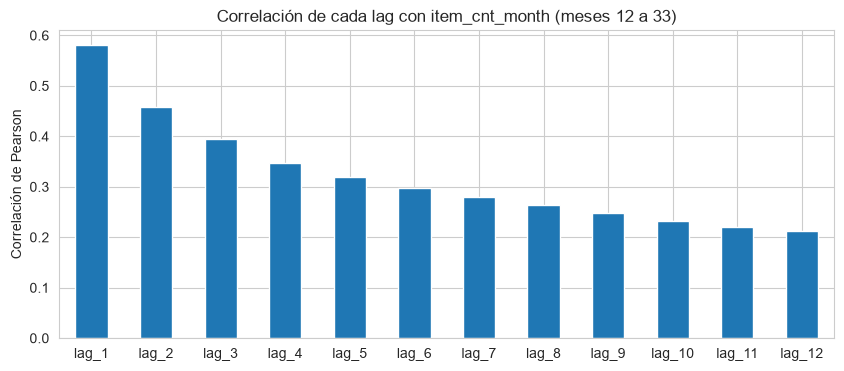

In [7]:
# Correlación de cada lag con la variable objetivo.
# Solo se usan los meses 12 a 33: desde el mes 12 todos los lags tienen historia completa
# y el mes 34 no tiene valor real.
datos_corr = mensual[(mensual["date_block_num"] >= 12) & (mensual["date_block_num"] <= 33)]

columnas_lag = ["lag_" + str(k) for k in range(1, 13)]
correlaciones = datos_corr[columnas_lag].corrwith(datos_corr["item_cnt_month"])

print(correlaciones.round(3))

correlaciones.plot(kind="bar", figsize=(10, 4))
plt.title("Correlación de cada lag con item_cnt_month (meses 12 a 33)")
plt.ylabel("Correlación de Pearson")
plt.xticks(rotation=0)
plt.show()

In [8]:
# ¿Qué tan seguido el lag tiene información (es distinto de 0)?
porcentaje_no_cero = (datos_corr[columnas_lag] > 0).mean() * 100
print("Porcentaje de filas con lag mayor a 0:")
print(porcentaje_no_cero.round(2))

Porcentaje de filas con lag mayor a 0:
lag_1    14.040
lag_2    13.950
lag_3    13.740
lag_4    13.510
lag_5    13.320
lag_6    13.110
lag_7    12.800
lag_8    12.370
lag_9    11.910
lag_10   11.540
lag_11   11.010
lag_12   10.620
dtype: float64


**Interpretación y selección de lags (sección 3):**

| Lag | Correlación | % filas con lag > 0 |
|---|---|---|
| lag_1 | **0.581** | 14.04% |
| lag_2 | **0.457** | 13.95% |
| lag_3 | **0.394** | 13.74% |
| lag_4 | 0.347 | 13.51% |
| lag_6 | 0.298 | 13.11% |
| lag_12 | 0.213 | 10.62% |

- La correlación **baja de forma constante** a medida que el lag es más lejano: la venta del mes pasado es la que
  más se parece a la venta de este mes. Esto coincide con la ACF/PACF del EDA, donde el rezago 1 era el más
  significativo.
- **El lag 12 es el más débil de todos (0.213).** Aunque en el EDA se vio el pico de diciembre en las ventas totales,
  a nivel de cada par tienda-producto el mismo mes del año anterior casi no ayuda. Además, usarlo obligaría a perder
  los primeros 12 meses. La estacionalidad se captura mejor con la variable `mes`.
- **Decisión:** se usan **`lag_1`, `lag_2` y `lag_3`**, los tres con mayor correlación. Los lags 4 a 12 aportan
  cada vez menos y repiten información de los primeros.

In [9]:
# Lags elegidos (según la correlación de arriba y la ACF/PACF del EDA)
LAGS_ELEGIDOS = [1, 2, 3]

columnas_lag_elegidas = ["lag_" + str(k) for k in LAGS_ELEGIDOS]
columnas_lag_descartadas = [c for c in columnas_lag if c not in columnas_lag_elegidas]

mensual = mensual.drop(columns=columnas_lag_descartadas)
print("Lags que se quedan:", columnas_lag_elegidas)

Lags que se quedan: ['lag_1', 'lag_2', 'lag_3']


## 4. Otras variables candidatas

Además de los lags del par, se crean variables que describen a la **tienda** y al **producto** (las variables
exógenas que pide la consigna) y al **momento del año**. Todas usan solo información de meses anteriores, salvo las
que son fijas (como la ciudad o la categoría).

| Variable | Qué mide | Por qué (según el EDA) |
|---|---|---|
| `mes` | Mes del año (1 a 12) | Diciembre vende mucho más que el resto (estacionalidad). |
| `item_category_id` | Categoría del producto | Las categorías tienen niveles y tendencias distintas. |
| `grupo_categoria` | Grupo de la categoría (primera parte del nombre, por ejemplo `Игры` = Juegos) | Junta categorías parecidas. |
| `ciudad` | Primera palabra del nombre de la tienda | Tiendas de la misma ciudad pueden parecerse. |
| `tienda_online` | 1 si es la tienda en línea (12) o el almacén digital (55) | En el EDA se comportaban distinto a las tiendas físicas. |
| `venta_tienda_lag_1` | Promedio de ventas por producto de la tienda el mes anterior | Tamaño y actividad reciente de la tienda. |
| `venta_producto_lag_1` | Promedio de ventas del producto en todas las tiendas el mes anterior | Popularidad reciente del producto. |
| `precio_producto_lag_1` | Precio promedio del producto el mes anterior | El precio afecta las unidades vendidas. |
| `meses_desde_primera_venta` | Meses desde la primera venta del producto | Los productos nuevos tienen un pico y luego caen (caso *GTA V*). |

In [10]:
# Mes del año (date_block_num 0 = enero)
mensual["mes"] = (mensual["date_block_num"] % 12 + 1).astype("int8")

# Categoría del producto
mensual = mensual.merge(items[["item_id", "item_category_id"]], on="item_id", how="left")

# Grupo de la categoría: lo que va antes del " - " en el nombre
categories["grupo_categoria"] = categories["item_category_name"].str.split(" - ").str[0].str.strip()
mensual = mensual.merge(categories[["item_category_id", "grupo_categoria"]], on="item_category_id", how="left")

# Ciudad: primera palabra del nombre de la tienda (sin el signo "!")
shops["ciudad"] = shops["shop_name"].str.replace("!", "").str.split(" ").str[0]
mensual = mensual.merge(shops[["shop_id", "ciudad"]], on="shop_id", how="left")

# Bandera de tienda en línea
mensual["tienda_online"] = mensual["shop_id"].isin([12, 55]).astype("int8")

print("Grupos de categoría:", mensual["grupo_categoria"].nunique())
print("Ciudades:", mensual["ciudad"].nunique())

Grupos de categoría: 20


Ciudades: 31


In [11]:
# Promedio de ventas de la tienda el mes anterior
promedio_tienda = mensual.groupby(["date_block_num", "shop_id"])["item_cnt_month"].mean().reset_index()
promedio_tienda["date_block_num"] = promedio_tienda["date_block_num"] + 1      # pasa al mes siguiente
promedio_tienda = promedio_tienda.rename(columns={"item_cnt_month": "venta_tienda_lag_1"})
mensual = mensual.merge(promedio_tienda, on=["date_block_num", "shop_id"], how="left")

# Promedio de ventas del producto (en todas las tiendas) el mes anterior
promedio_producto = mensual.groupby(["date_block_num", "item_id"])["item_cnt_month"].mean().reset_index()
promedio_producto["date_block_num"] = promedio_producto["date_block_num"] + 1
promedio_producto = promedio_producto.rename(columns={"item_cnt_month": "venta_producto_lag_1"})
mensual = mensual.merge(promedio_producto, on=["date_block_num", "item_id"], how="left")

# Si el producto no se vendió el mes anterior, su promedio de ventas es 0
mensual["venta_producto_lag_1"] = mensual["venta_producto_lag_1"].fillna(0)

In [12]:
# Precio promedio del producto el mes anterior (se deja vacío si no se vendió)
precio_producto = sales.groupby(["date_block_num", "item_id"])["item_price"].mean().reset_index()
precio_producto["date_block_num"] = precio_producto["date_block_num"] + 1
precio_producto = precio_producto.rename(columns={"item_price": "precio_producto_lag_1"})
mensual = mensual.merge(precio_producto, on=["date_block_num", "item_id"], how="left")

# Meses desde la primera venta del producto
primera_venta = sales.groupby("item_id")["date_block_num"].min()
mensual["meses_desde_primera_venta"] = mensual["date_block_num"] - mensual["item_id"].map(primera_venta)

# Los productos de test que nunca se vendieron no tienen primera venta: son nuevos, así que llevan 0 meses
mensual["meses_desde_primera_venta"] = mensual["meses_desde_primera_venta"].fillna(0)

mensual.head()

,date_block_num,shop_id,item_id,item_cnt_month,lag_1,lag_2,lag_3,mes,item_category_id,grupo_categoria,ciudad,tienda_online,venta_tienda_lag_1,venta_producto_lag_1,precio_producto_lag_1,meses_desde_primera_venta
0,0,59,22154,1.000,0.000,0.000,0.000,1,37,Кино,Ярославль,0,NaN,0.000,NaN,0.000
1,0,59,2552,0.000,0.000,0.000,0.000,1,58,Музыка,Ярославль,0,NaN,0.000,NaN,0.000
2,0,59,2554,0.000,0.000,0.000,0.000,1,58,Музыка,Ярославль,0,NaN,0.000,NaN,0.000
3,0,59,2555,0.000,0.000,0.000,0.000,1,56,Музыка,Ярославль,0,NaN,0.000,NaN,0.000
4,0,59,2564,0.000,0.000,0.000,0.000,1,59,Музыка,Ярославль,0,NaN,0.000,NaN,0.000


In [13]:
# Revisar valores vacíos en las variables nuevas
mensual.isnull().sum()

date_block_num                     0
shop_id                            0
item_id                            0
item_cnt_month                214200
lag_1                              0
lag_2                              0
lag_3                              0
mes                                0
item_category_id                   0
grupo_categoria                    0
ciudad                             0
tienda_online                      0
venta_tienda_lag_1            480173
venta_producto_lag_1               0
precio_producto_lag_1        2407390
meses_desde_primera_venta          0
dtype: int64

**Interpretación (sección 4):**

- `item_cnt_month` está vacío en **214,200 filas**: son las del mes 34 (test), que es lo que se quiere predecir.
- `venta_tienda_lag_1` está vacía en **480,173 filas** (la tienda no vendió el mes anterior) y
  `precio_producto_lag_1` en **2,407,390 filas** (el producto no se vendió el mes anterior). Estos vacíos son
  **naturales** y se revisan en la sección 6.i.
- `meses_desde_primera_venta` ya no tiene vacíos: los productos nuevos de test quedaron con 0.
- Hay **20 grupos de categoría** y **31 ciudades** (tres de ellas no son ciudades reales: `Выездная` = ventas fuera
  de tienda, `Интернет-магазин` = tienda en línea y `Цифровой` = almacén digital).

## 5. División en entrenamiento y validación

Como es un problema de *forecasting*, la división se hace **en orden de tiempo** y no al azar (nota importante de la
consigna):
- **Entrenamiento:** meses 0 a 26 (el primer 80% de los meses).
- **Validación:** meses 27 a 33 (el 20% final).
- **Test:** mes 34.

Es la división que indica la consigna. En los primeros meses (0, 1 y 2) algunos lags no tienen meses anteriores, así
que quedan en 0. En el mes 0 tampoco hay venta de la tienda ni precio del mes anterior, así que esas variables quedan
vacías (se revisan en la sección 6.i).

Todas las operaciones de esta sección **se ajustan solo con el set de entrenamiento** y se muestran sobre él, igual que
en clase.

In [14]:
PRIMER_MES = 0

train = mensual[(mensual["date_block_num"] >= PRIMER_MES) & (mensual["date_block_num"] <= 26)].copy()
valid = mensual[(mensual["date_block_num"] >= 27) & (mensual["date_block_num"] <= 33)].copy()
test_34 = mensual[mensual["date_block_num"] == 34].copy()

print("Entrenamiento:", train.shape)
print("Validación   :", valid.shape)
print("Test (mes 34):", test_34.shape)

Entrenamiento: (9299486, 16)
Validación   : (1614364, 16)
Test (mes 34): (214200, 16)


## 6. (1b) Procesos de ingeniería de características

Se aplica al menos una operación de cada proceso, con la librería **feature-engine** que se usó en clase. Para cada
uno se indica el **criterio** de la elección.

### 6.i Imputación de variables numéricas

Dos variables numéricas quedan vacías de forma natural:
- `precio_producto_lag_1`: vacía cuando el producto no se vendió el mes anterior (no hay precio que observar).
- `venta_tienda_lag_1`: vacía cuando la tienda no vendió el mes anterior (tiendas nuevas o que venden solo algunos
  meses, como la tienda 9).

Se usa **la misma regla de clase** según el porcentaje de faltantes en entrenamiento:
- ≤ 5%: **mediana** (`MeanMedianImputer`).
- Entre 5% y 20%: **muestreo aleatorio** (`RandomSampleImputer`), que rellena con valores observados tomados al azar y
  conserva la distribución.
- Más de 20%: descartar la variable.

In [15]:
UMBRAL_MEDIANA = 5
UMBRAL_DESCARTE = 20

variables_con_vacios = ["precio_producto_lag_1", "venta_tienda_lag_1"]
porcentaje_faltante = train[variables_con_vacios].isnull().mean() * 100
print("Porcentaje de faltantes en entrenamiento:")
print(porcentaje_faltante.round(2))

# Aplicar la regla de clase
num_mediana = [c for c in variables_con_vacios if porcentaje_faltante[c] <= UMBRAL_MEDIANA]
num_muestreo = [c for c in variables_con_vacios if UMBRAL_MEDIANA < porcentaje_faltante[c] <= UMBRAL_DESCARTE]
num_descartar = [c for c in variables_con_vacios if porcentaje_faltante[c] > UMBRAL_DESCARTE]

print()
print("Mediana          :", num_mediana)
print("Muestreo aleatorio:", num_muestreo)
print("Descartar        :", num_descartar)

Porcentaje de faltantes en entrenamiento:
precio_producto_lag_1   21.760
venta_tienda_lag_1       4.880
dtype: float64

Mediana          : ['venta_tienda_lag_1']
Muestreo aleatorio: []
Descartar        : ['precio_producto_lag_1']


In [16]:
# Quitar las variables con más de 20% de faltantes (regla de clase)
train = train.drop(columns=num_descartar)

imputador_mediana = MeanMedianImputer(imputation_method="median", variables=num_mediana)
imputador_mediana.fit(train)
print("Mediana aprendida:", imputador_mediana.imputer_dict_)

train_imp = imputador_mediana.transform(train)
print("Faltantes después de imputar:")
print(train_imp[num_mediana].isnull().sum())

Mediana aprendida: {'venta_tienda_lag_1': 0.23900206387043}


Faltantes después de imputar:
venta_tienda_lag_1    0
dtype: int64


### 6.ii Imputación de variables categóricas

Las variables categóricas (`ciudad`, `grupo_categoria`) **no tienen valores vacíos**. Como pide la consigna, se
**fuerza** el proceso: se borra al azar el 5% de sus valores en el set de entrenamiento y luego se imputa con la
**moda** (el valor más frecuente), igual que en clase.

In [17]:
train_forzado = train_imp.copy()

# Borrar al azar el 5% de los valores de cada variable categórica
for columna in ["ciudad", "grupo_categoria"]:
    filas_a_borrar = train_forzado.sample(frac=0.05, random_state=RANDOM_STATE).index
    train_forzado.loc[filas_a_borrar, columna] = np.nan

print("Vacíos forzados:")
print(train_forzado[["ciudad", "grupo_categoria"]].isnull().sum())

Vacíos forzados:


ciudad             464974
grupo_categoria    464974
dtype: int64


In [18]:
imputador_categorico = CategoricalImputer(imputation_method="frequent", variables=["ciudad", "grupo_categoria"])
imputador_categorico.fit(train_forzado)

print("Moda aprendida:", imputador_categorico.imputer_dict_)

train_cat = imputador_categorico.transform(train_forzado)
print("Vacíos después de imputar:", train_cat[["ciudad", "grupo_categoria"]].isnull().sum().sum())

Moda aprendida: {'ciudad': 'Москва', 'grupo_categoria': 'Кино'}


Vacíos después de imputar: 0


### 6.iii Codificación de variables categóricas

Los modelos necesitan números. Se usa **One-Hot** (una columna 0/1 por cada valor), como en clase con las variables
nominales, porque ni la ciudad ni el grupo de categoría tienen un orden natural.

Se revisa cuántas columnas se crearían para no generar demasiadas.

In [19]:
print("Valores distintos en entrenamiento:")
print("ciudad          :", train_cat["ciudad"].nunique())
print("grupo_categoria :", train_cat["grupo_categoria"].nunique())
print("shop_id         :", train_cat["shop_id"].nunique())
print("item_category_id:", train_cat["item_category_id"].nunique())

Valores distintos en entrenamiento:


ciudad          : 31


grupo_categoria : 20
shop_id         : 56
item_category_id: 81


In [20]:
codificador = OneHotEncoder(variables=["ciudad", "grupo_categoria"])
codificador.fit(train_cat)

train_cod = codificador.transform(train_cat)
print("Columnas antes:", train_cat.shape[1], "-> después:", train_cod.shape[1])
print("Ejemplo de columnas nuevas:", [c for c in train_cod.columns if c.startswith("grupo_categoria_")][:5])

Columnas antes: 15 -> después: 64
Ejemplo de columnas nuevas: ['grupo_categoria_Кино', 'grupo_categoria_Музыка', 'grupo_categoria_Игры', 'grupo_categoria_Игры PC', 'grupo_categoria_Программы']


### 6.iv Tratamiento de outliers

El precio se descartó en 6.i, así que el tratamiento de outliers se aplica a una cantidad: `venta_producto_lag_1`
(ventas promedio del producto el mes anterior). Algunos productos tienen meses con ventas muy altas, por ejemplo en
su lanzamiento. Se usa **Winsorizer** (capping), igual que en clase: los valores muy altos se **recortan** al límite
en lugar de borrar filas.

Para la variable objetivo, el recorte a [0, 20] ya se hizo en la sección 2.

In [21]:
print(train_cod["venta_producto_lag_1"].describe())

count   9,299,486.000
mean            0.289
std             0.866
min             0.000
25%             0.020
50%             0.080
75%             0.224
max            19.556
Name: venta_producto_lag_1, dtype: float64


La variable está muy sesgada: la **mediana es 0.08** unidades pero el **máximo es 19.56**. Si se usara la regla IQR
de clase, el límite sería Q3 + 1.5 × IQR = 0.224 + 1.5 × 0.204 = **0.53**, y se recortaría el **11.2%** de las filas,
que incluye productos con ventas normales. Por eso se recorta solo el **1% más alto** (percentil 99).

In [22]:
recortador = Winsorizer(capping_method="quantiles", tail="right", fold=0.01,
                        variables=["venta_producto_lag_1"])
recortador.fit(train_cod)

print("Límite superior aprendido:", recortador.right_tail_caps_)

train_out = recortador.transform(train_cod)
filas_recortadas = (train_cod["venta_producto_lag_1"] != train_out["venta_producto_lag_1"]).sum()
print("Filas recortadas:", filas_recortadas)
print("Máximo después:", train_out["venta_producto_lag_1"].max())

Límite superior aprendido: {'venta_producto_lag_1': 3.82608699798584}


Filas recortadas: 92698
Máximo después: 3.826087


### 6.v Transformación de variables numéricas

Igual que en clase, se aplica **Yeo-Johnson** a las variables continuas con sesgo mayor a 0.75 (en valor absoluto).
Yeo-Johnson, a diferencia del logaritmo, acepta ceros, y aquí hay muchos ceros (pares sin ventas).

In [23]:
variables_continuas = columnas_lag_elegidas + ["venta_tienda_lag_1", "venta_producto_lag_1"]

sesgo_antes = train_out[variables_continuas].skew()
print("Sesgo antes:")
print(sesgo_antes.round(3))

Sesgo antes:
lag_1                  9.479
lag_2                  9.684
lag_3                  9.962
venta_tienda_lag_1     2.302
venta_producto_lag_1   4.336
dtype: float32


In [24]:
UMBRAL_SESGO = 0.75
variables_yj = sesgo_antes[sesgo_antes.abs() > UMBRAL_SESGO].index.tolist()
print("Variables a transformar:", variables_yj)

transformador = YeoJohnsonTransformer(variables=variables_yj)
transformador.fit(train_out)
train_tr = transformador.transform(train_out)

resumen_transformacion = pd.DataFrame({
    "sesgo_antes": sesgo_antes,
    "sesgo_despues": train_tr[variables_continuas].skew(),
})
resumen_transformacion

Variables a transformar: ['lag_1', 'lag_2', 'lag_3', 'venta_tienda_lag_1', 'venta_producto_lag_1']


,sesgo_antes,sesgo_despues
lag_1,9.479,2.107
lag_2,9.684,2.200
lag_3,9.962,2.310
venta_tienda_lag_1,2.302,0.098
venta_producto_lag_1,4.336,0.619


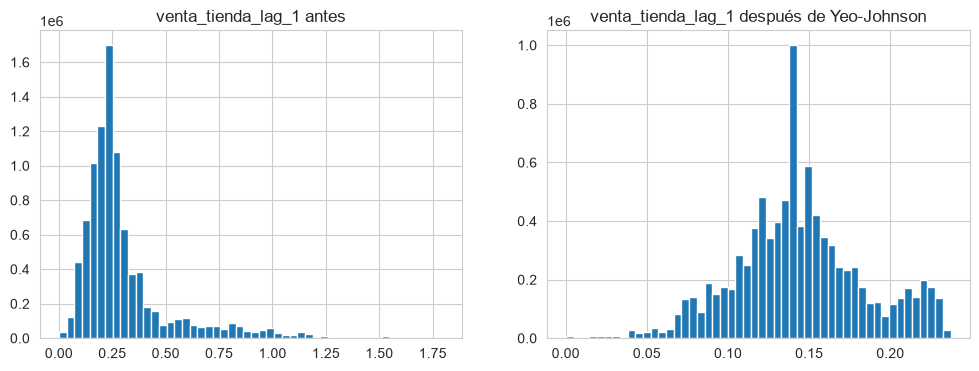

In [25]:
# Ejemplo visual con la venta promedio de la tienda
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(train_out["venta_tienda_lag_1"], bins=50)
ax[0].set_title("venta_tienda_lag_1 antes")
ax[1].hist(train_tr["venta_tienda_lag_1"], bins=50)
ax[1].set_title("venta_tienda_lag_1 después de Yeo-Johnson")
plt.show()

### 6.vi Escalado de características

Se usa **StandardScaler** (media 0 y desviación estándar 1), como en clase. Es importante para los modelos lineales
(Ridge, Lasso, ElasticNet) y la red neuronal (MLP), porque las variables tienen escalas muy distintas: por ejemplo,
el mes va de 1 a 12 y los meses desde la primera venta llegan a 33. Las columnas One-Hot y la bandera
`tienda_online` no se escalan porque ya son 0/1.

In [26]:
variables_escalar = variables_continuas + ["mes", "meses_desde_primera_venta"]

escalador = SklearnTransformerWrapper(transformer=StandardScaler(), variables=variables_escalar)
escalador.fit(train_tr)
train_esc = escalador.transform(train_tr)

train_esc[variables_escalar].describe().loc[["mean", "std"]].round(2)

,lag_1,lag_2,lag_3,venta_tienda_lag_1,venta_producto_lag_1,mes,meses_desde_primera_venta
mean,-0.000,0.000,-0.000,0.000,0.000,-0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000


**Resumen de la sección 6 (criterios y resultados):**

| Proceso | Operación | Variables | Criterio | Resultado |
|---|---|---|---|---|
| i. Imputación numérica | Descartar | `precio_producto_lag_1` | Regla de clase: 21.76% de faltantes (más de 20%) | La variable no entra al modelo |
| i. Imputación numérica | `MeanMedianImputer` (mediana) | `venta_tienda_lag_1` | Regla de clase: 4.88% de faltantes (≤ 5%) | Mediana = 0.239; 0 vacíos |
| ii. Imputación categórica | `CategoricalImputer` (moda) | `ciudad`, `grupo_categoria` | No había vacíos: se **forzó** borrando el 5% al azar (464,974 filas por variable) | Moda: `Москва` (Moscú) y `Кино` (Cine); 0 vacíos |
| iii. Codificación | `OneHotEncoder` | `ciudad`, `grupo_categoria` | Variables nominales sin orden, como en clase | De 15 a 64 columnas (31 ciudades + 20 grupos) |
| iv. Outliers | `Winsorizer` (percentil 99) | `venta_producto_lag_1` | Ventas extremas de algunos productos; con IQR se recortaría el 11.2% de las filas | Límite 3.83; se recortaron 92,698 filas (1%) |
| v. Transformación | `YeoJohnsonTransformer` | lags y promedios de tienda y producto | Regla de clase: sesgo mayor a 0.75; acepta ceros | Ejemplo: venta de tienda de 2.302 a 0.098; venta de producto de 4.336 a 0.619 |
| vi. Escalado | `StandardScaler` | continuas, `mes`, `meses_desde_primera_venta` | Escalas muy distintas; necesario para modelos lineales y MLP | Media 0 y desviación 1 en todas |

Observaciones:
- **¿Por qué se descartó el precio?** Al entrenar desde el mes 0, como pide la consigna, el mes 0 no tiene precio
  del mes anterior, y el porcentaje de vacíos sube a 21.76%. Según la regla de clase, una variable con más de 20% de
  faltantes se descarta.
- Los lags siguen con sesgo cercano a 2 después de Yeo-Johnson (bajó desde 9). No se puede bajar más porque la gran
  mayoría de los valores son 0: muchos ceros iguales hacen que la distribución no pueda ser simétrica.
- No se hace One-Hot de `shop_id` (56 tiendas) ni de `item_category_id` (81 categorías) para no crear más de 100
  columnas extra sobre más de 9 millones de filas. La información de la tienda entra por `ciudad`, `tienda_online` y
  `venta_tienda_lag_1`, y la del producto por `grupo_categoria`, `venta_producto_lag_1` y
  `meses_desde_primera_venta`.

## 7. (1c) Lista final del proceso

### Variables del modelo

**Variable objetivo:** `item_cnt_month`, recortada a [0, 20].

**Variables de entrada (10):**

| Tipo | Variables |
|---|---|
| Lags del par tienda-producto | `lag_1`, `lag_2`, `lag_3` |
| Exógenas de la tienda | `ciudad`, `tienda_online`, `venta_tienda_lag_1` |
| Exógenas del producto | `grupo_categoria`, `venta_producto_lag_1`, `meses_desde_primera_venta` |
| Tiempo | `mes` |

`date_block_num`, `shop_id`, `item_id` e `item_category_id` se usan para construir las variables y para separar los
datos por mes, pero no entran directamente al modelo como números. `precio_producto_lag_1` se descartó por tener
más de 20% de faltantes.

### Transformaciones que se aplicarán en el pipeline (en este orden)

1. **Mapeo de nombres** (Mapper): traducir `ciudad` y `grupo_categoria` del ruso al español con un diccionario.
2. **Imputación numérica:** mediana en `venta_tienda_lag_1`.
3. **Imputación categórica:** moda en `ciudad` y `grupo_categoria`.
4. **Codificación:** One-Hot en `ciudad` y `grupo_categoria`.
5. **Outliers:** Winsorizer al percentil 99 en `venta_producto_lag_1`.
6. **Transformación:** Yeo-Johnson en `lag_1`, `lag_2`, `lag_3`, `venta_tienda_lag_1` y `venta_producto_lag_1`.
7. **Escalado:** StandardScaler en las 5 variables anteriores, `mes` y `meses_desde_primera_venta`.

### Mecanismos de mapeo

| Mapeo | De → a | Dónde se aplica |
|---|---|---|
| Tiendas repetidas | `{0: 57, 1: 58, 11: 10}` | Limpieza de datos, antes del pipeline |
| Tienda → ciudad | Primera palabra del nombre de la tienda (sin `!`) | Al construir la tabla mensual |
| Categoría → grupo | Texto antes de ` - ` en el nombre de la categoría | Al construir la tabla mensual |
| Ciudad y grupo → español | Diccionario ruso → español. Ejemplo: `Москва` → Moscú, `Игры` → Juegos de consola, `Кино` → Cine | **Mapper** dentro del pipeline (notebook 03) |
| Fuera de rango | `item_cnt_month` → recorte a [0, 20] | Al construir la variable objetivo |

### Datos de entrenamiento y validación

- **Entrenamiento:** meses 0 a 26 (9,299,486 filas), el primer 80% de los meses.
- **Validación:** meses 27 a 33 (1,614,364 filas), el 20% final.
- **Test:** mes 34 (214,200 filas).
- La división es en orden de tiempo, y todas las transformaciones se ajustan solo con entrenamiento.

## 8. Guardar la tabla mensual

Se guarda la tabla mensual con todas las variables candidatas (sin transformar) en `data/processed/`. El notebook 03
la usa para construir el pipeline. El archivo no se sube a GitHub porque la carpeta `data/` está excluida.

In [27]:
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
mensual.to_parquet(PROCESSED_DATA_DIR / "ventas_mensuales.parquet", index=False)

print("Guardado:", PROCESSED_DATA_DIR / "ventas_mensuales.parquet")
print("Filas:", len(mensual), "| Columnas:", mensual.shape[1])
print(list(mensual.columns))

Guardado: C:\Users\brady\OneDrive - Universidad Galileo\Documentos\PRODUCT DEVELOPMENT\Proyecto-1\data\processed\ventas_mensuales.parquet
Filas: 11128050 | Columnas: 16
['date_block_num', 'shop_id', 'item_id', 'item_cnt_month', 'lag_1', 'lag_2', 'lag_3', 'mes', 'item_category_id', 'grupo_categoria', 'ciudad', 'tienda_online', 'venta_tienda_lag_1', 'venta_producto_lag_1', 'precio_producto_lag_1', 'meses_desde_primera_venta']
